# ShotShield v2 — Gunshot detection in urban audio

A CNN that listens to a 4-second audio clip and answers one question: **was a gunshot fired?**
It is trained on all 8,732 clips of [UrbanSound8K](https://urbansounddataset.weebly.com/urbansound8k.html):
`gun_shot` against **every other urban sound** (sirens, drilling, car horns, dogs, jackhammers, ...).

**What changed from v1**
| v1 | v2 |
|---|---|
| Gunshot vs dog bark only | Gunshot vs all 9 other classes |
| Short clips padded with 0 dB (the *loudest* value) | Short clips loop-padded with real audio — no "clip length" shortcut |
| Random train/test split (slices of one recording on both sides) | The dataset's official 10 folds + 10-fold cross-validation |
| Accuracy only | Precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix |
| 5.2M parameters (Flatten → Dense) | ~0.3M parameters (global pooling) |
| Label order not saved | Model + `model_info.json` (labels, threshold, feature settings) |

**Before you run this notebook on Kaggle**
1. **Add data** → search **UrbanSound8K** → add it (any version with the `fold1`…`fold10` folders works).
2. **Settings → Accelerator → GPU** (T4 or P100).
3. **Run All.** With cross-validation this takes roughly 40–60 minutes; set `RUN_CV = False` below for a ~10 minute run.
4. When it finishes, download **`shotshield_v2_outputs.zip`** from the Output panel (download the *zip*, not the files inside it).

In [1]:
import os, gc, glob, json, time, shutil, hashlib, datetime

import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
import keras
from keras import layers

# ---- Settings -------------------------------------------------------------
SEED = 42
RUN_CV = True          # 10-fold cross-validation (the honest headline numbers). False = only train the final model.
EPOCHS = 40            # upper bound; early stopping usually ends sooner
BATCH_SIZE = 64

OUT_DIR = '/kaggle/working/shotshield_v2'
ASSET_DIR = os.path.join(OUT_DIR, 'assets')
CACHE_FILE = '/tmp/us8k_logmel.npy'   # /tmp is not part of the notebook output
os.makedirs(ASSET_DIR, exist_ok=True)

keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, '| Keras', keras.__version__, '| librosa', librosa.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'none — turn on a GPU in Settings → Accelerator')

TensorFlow 2.21.0 | Keras 3.13.2 | librosa 0.11.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the metadata
The dataset's folder layout differs between Kaggle versions, so the paths are found automatically.

In [2]:
INPUT_DIR = '/kaggle/input'
csv_hits, fold1_hits = [], []
for root, dirs, files in os.walk(INPUT_DIR, followlinks=True):
    csv_hits += [os.path.join(root, f) for f in files if f.lower() == 'urbansound8k.csv']
    fold1_hits += [os.path.join(root, d) for d in dirs if d.lower() == 'fold1']

if not csv_hits or not fold1_hits:
    print('What is attached under /kaggle/input (first 3 levels):')
    for root, dirs, files in os.walk(INPUT_DIR, followlinks=True):
        depth = root[len(INPUT_DIR):].count(os.sep)
        if depth < 3:
            print('  ' * depth + (os.path.basename(root) or root) + '/', f'({len(files)} files)')
    raise FileNotFoundError('UrbanSound8K not found. Click "Add Input", search "UrbanSound8K", add it, '
                            'then run this cell again. Found metadata CSV: %s, fold1 folder: %s'
                            % (bool(csv_hits), bool(fold1_hits)))

META_CSV, AUDIO_ROOT = sorted(csv_hits)[0], os.path.dirname(sorted(fold1_hits)[0])
print('metadata:', META_CSV)
print('audio:   ', AUDIO_ROOT)

meta = pd.read_csv(META_CSV)
meta['path'] = [os.path.join(AUDIO_ROOT, f'fold{f}', n) for f, n in zip(meta['fold'], meta['slice_file_name'])]
meta['is_gunshot'] = (meta['class'] == 'gun_shot').astype(int)
meta['duration'] = meta['end'] - meta['start']
missing = (~meta['path'].map(os.path.exists)).sum()
print(f'{len(meta)} clips, {missing} missing files')
meta['class'].value_counts()

metadata: /kaggle/input/datasets/chrisfilo/urbansound8k/UrbanSound8K.csv
audio:    /kaggle/input/datasets/chrisfilo/urbansound8k
8732 clips, 0 missing files


class
dog_bark            1000
children_playing    1000
air_conditioner     1000
street_music        1000
jackhammer          1000
engine_idling       1000
drilling            1000
siren                929
car_horn             429
gun_shot             374
Name: count, dtype: int64

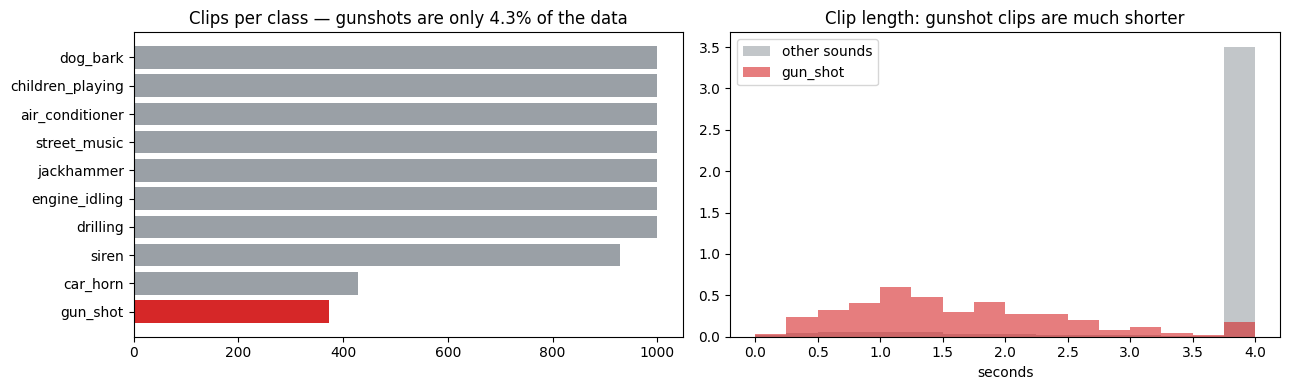

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = meta['class'].value_counts()
axes[0].barh(counts.index, counts.values, color=['#d62728' if c == 'gun_shot' else '#9aa0a6' for c in counts.index])
axes[0].set_title('Clips per class — gunshots are only %.1f%% of the data' % (100 * meta['is_gunshot'].mean()))
axes[0].invert_yaxis()

bins = np.linspace(0, 4, 17)
axes[1].hist(meta.loc[meta.is_gunshot == 0, 'duration'], bins=bins, density=True, alpha=0.6, label='other sounds', color='#9aa0a6')
axes[1].hist(meta.loc[meta.is_gunshot == 1, 'duration'], bins=bins, density=True, alpha=0.6, label='gun_shot', color='#d62728')
axes[1].set_title('Clip length: gunshot clips are much shorter')
axes[1].set_xlabel('seconds'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{ASSET_DIR}/dataset_overview.png', dpi=130); plt.show()

The right-hand plot is why v1's padding was a problem: most gunshot clips are short, most other clips are a full 4 s.
If short clips are padded with an unusual value, a model can learn "padding ⇒ gunshot" instead of the sound itself.

## 2. Audio → log-mel spectrogram
Every clip becomes a 128 × 173 image: 128 mel frequency bands × 173 time frames (4 s at 22,050 Hz, hop 512).
Clips shorter than 4 s are **looped** to fill the window, so the model never sees artificial silence.
Values are scaled to 0–1 (0 = 80 dB below the clip's peak, 1 = the peak).

*These settings must match `src/shotshield/features.py` in the repository.*

In [4]:
SAMPLE_RATE = 22050
CLIP_SECONDS = 4.0
N_SAMPLES = int(SAMPLE_RATE * CLIP_SECONDS)
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512
TOP_DB = 80.0
N_FRAMES = 1 + N_SAMPLES // HOP_LENGTH   # 173


def loop_pad(y, n=N_SAMPLES):
    """Repeat a short clip until it fills n samples; trim a long one."""
    if len(y) == 0:
        return np.zeros(n, dtype=np.float32)
    if len(y) < n:
        y = np.tile(y, int(np.ceil(n / len(y))))
    return y[:n].astype(np.float32)


def log_mel(y):
    """4 s waveform -> (N_MELS, N_FRAMES) log-mel spectrogram scaled to [0, 1]."""
    mel = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    if mel.max() < 1e-10:                      # digital silence
        return np.zeros((N_MELS, N_FRAMES), dtype=np.float32)
    db = librosa.power_to_db(mel, ref=np.max, top_db=TOP_DB)
    return ((db + TOP_DB) / TOP_DB).astype(np.float32)


def clip_features(path):
    y, _ = librosa.load(path, sr=SAMPLE_RATE, mono=True)
    return log_mel(loop_pad(y))


def safe_features(path):
    try:
        return clip_features(path)
    except Exception as e:
        print('skipped', os.path.basename(path), '-', e)
        return None

In [5]:
t0 = time.time()
if os.path.exists(CACHE_FILE):          # re-running in the same session: skip the slow part
    X = np.load(CACHE_FILE)
    ok = np.load(CACHE_FILE.replace('.npy', '_ok.npy'))
    print('Loaded cached features')
else:
    feats = Parallel(n_jobs=-1, verbose=2)(delayed(safe_features)(p) for p in meta['path'])
    ok = np.array([f is not None for f in feats])
    X = np.stack([f for f in feats if f is not None])[..., np.newaxis]
    np.save(CACHE_FILE, X)
    np.save(CACHE_FILE.replace('.npy', '_ok.npy'), ok)
    del feats
meta = meta[ok].reset_index(drop=True)
y = meta['is_gunshot'].values.astype(np.float32)
folds = meta['fold'].values
print(f'X {X.shape}, {X.nbytes / 1e9:.2f} GB, {int(y.sum())} gunshots — {time.time() - t0:.0f}s')

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:   26.5s
[Parallel(n_jobs=-1)]: Done 252 tasks      | elapsed:   32.2s
[Parallel(n_jobs=-1)]: Done 658 tasks      | elapsed:   42.6s
[Parallel(n_jobs=-1)]: Done 1224 tasks      | elapsed:   56.9s
[Parallel(n_jobs=-1)]: Done 1954 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 2844 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 3898 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 5112 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 6490 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done 8028 tasks      | elapsed:  3.7min
[Parallel(n_jobs=-1)]: Done 8725 out of 8732 | elapsed:  3.9min remaining:    0.2s
[Parallel(n_jobs=-1)]: Done 8732 out of 8732 | elapsed:  3.9min finished


X (8732, 128, 173, 1), 0.77 GB, 374 gunshots — 236s


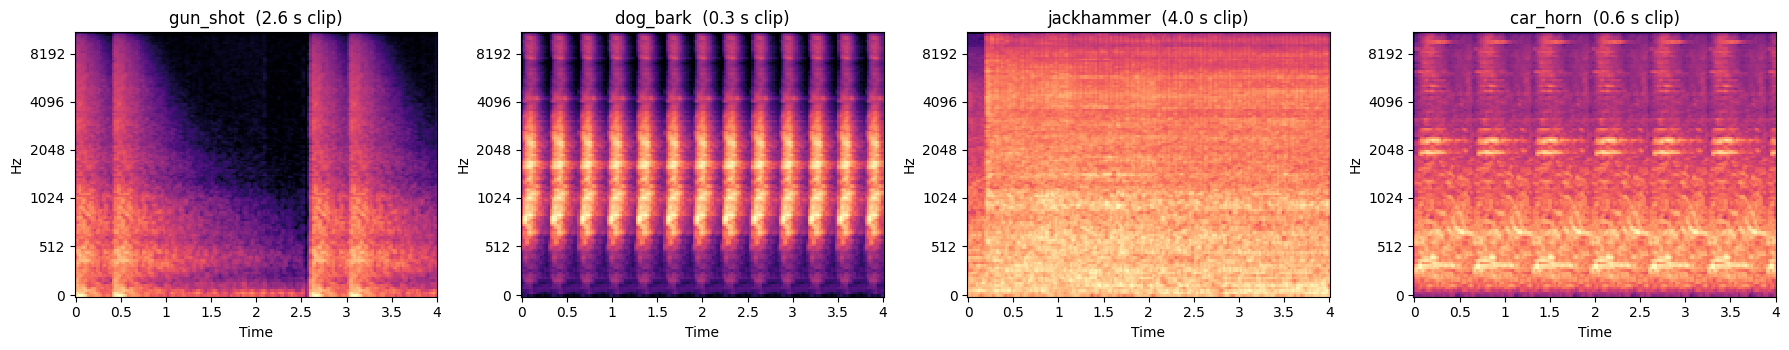

In [6]:
examples = ['gun_shot', 'dog_bark', 'jackhammer', 'car_horn']
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, cls in zip(axes, examples):
    i = meta.index[meta['class'] == cls][0]
    librosa.display.specshow(X[i, :, :, 0], sr=SAMPLE_RATE, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax, cmap='magma')
    ax.set_title(f'{cls}  ({meta.loc[i, "duration"]:.1f} s clip)')
plt.tight_layout(); plt.savefig(f'{ASSET_DIR}/example_spectrograms.png', dpi=130); plt.show()

## 3. Model
Three convolution blocks, then global average + max pooling instead of `Flatten`.
Global max pooling suits gunshots: a loud, short event anywhere in the clip is enough.
One sigmoid output = probability that the clip contains a gunshot.

In [7]:
def build_model(input_shape=(N_MELS, N_FRAMES, 1)):
    inp = keras.Input(shape=input_shape, name='log_mel')
    x = inp
    for filters in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(0.2)(x)
    x = layers.Concatenate()([layers.GlobalAveragePooling2D()(x), layers.GlobalMaxPooling2D()(x)])
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', name='gunshot_probability')(x)
    model = keras.Model(inp, out, name='shotshield_v2')
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc'), keras.metrics.AUC(curve='PR', name='pr_auc'),
                           keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')])
    return model


build_model().summary()

Model: "shotshield_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ log_mel             │ (None, 128, 173,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 173,  │        288 │ log_mel[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 173,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 173,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 173,  │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 173,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 128, 173,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 86,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64, 86,    │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 86,    │     18,432 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 86,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 64, 86,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 86,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 86,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 64, 86,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 43,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 43,    │          0 │ max_pooling2d_1[

 Total params: 304,289 (1.16 MB)

 Trainable params: 303,393 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [8]:
def train(train_idx, val_idx, verbose=0):
    keras.backend.clear_session()
    model = build_model()
    w = compute_class_weight('balanced', classes=np.array([0.0, 1.0]), y=y[train_idx])   # gunshots are rare
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=8, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc', mode='max', factor=0.5, patience=3, min_lr=1e-5),
    ]
    history = model.fit(X[train_idx], y[train_idx], validation_data=(X[val_idx], y[val_idx]),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight={0: w[0], 1: w[1]},
                        callbacks=callbacks, verbose=verbose)
    return model, history


def predict(model, idx):
    return model.predict(X[idx], batch_size=128, verbose=0).ravel()


def binary_metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average='binary', zero_division=0)
    return {'threshold': float(threshold), 'precision': float(p), 'recall': float(r), 'f1': float(f),
            'roc_auc': float(roc_auc_score(y_true, prob)), 'pr_auc': float(average_precision_score(y_true, prob)),
            'accuracy': float((pred == y_true).mean())}

## 4. 10-fold cross-validation (headline results)
UrbanSound8K's authors split it into 10 folds so that slices of the same recording never end up in both
training and test data. Each fold is the test set once; the next fold is used for early stopping; the other 8 train.

In [9]:
oof = np.full(len(y), np.nan)      # out-of-fold probability for every clip
cv_rows = []
if RUN_CV:
    for k in range(1, 11):
        val_k = k % 10 + 1
        test_idx = np.where(folds == k)[0]
        val_idx = np.where(folds == val_k)[0]
        train_idx = np.where((folds != k) & (folds != val_k))[0]
        t0 = time.time()
        model, history = train(train_idx, val_idx)
        oof[test_idx] = predict(model, test_idx)
        m = binary_metrics(y[test_idx], oof[test_idx])
        m.update(fold=k, epochs=len(history.history['loss']), minutes=round((time.time() - t0) / 60, 1))
        cv_rows.append(m)
        print(f"fold {k:2d} | precision {m['precision']:.3f} recall {m['recall']:.3f} F1 {m['f1']:.3f} "
              f"ROC-AUC {m['roc_auc']:.3f} | {m['epochs']} epochs, {m['minutes']} min")
        del model; gc.collect()

    cv_df = pd.DataFrame(cv_rows).set_index('fold')
    cv_df.to_csv(f'{OUT_DIR}/cv_results.csv')
    cv_summary = cv_df[['precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'accuracy']].agg(['mean', 'std'])
    display(cv_summary.round(3))
else:
    print('RUN_CV = False — skipping cross-validation')

fold  1 | precision 0.892 recall 0.943 F1 0.917 ROC-AUC 0.999 | 18 epochs, 5.6 min


fold  2 | precision 0.946 recall 1.000 F1 0.972 ROC-AUC 1.000 | 17 epochs, 4.9 min


fold  3 | precision 0.735 recall 1.000 F1 0.847 ROC-AUC 1.000 | 37 epochs, 9.9 min


fold  4 | precision 0.912 recall 0.816 F1 0.861 ROC-AUC 0.999 | 18 epochs, 5.1 min


fold  5 | precision 0.930 recall 1.000 F1 0.964 ROC-AUC 1.000 | 25 epochs, 7.0 min


fold  6 | precision 1.000 recall 0.804 F1 0.892 ROC-AUC 1.000 | 23 epochs, 6.6 min


fold  7 | precision 1.000 recall 0.725 F1 0.841 ROC-AUC 0.995 | 15 epochs, 4.5 min


fold  8 | precision 1.000 recall 1.000 F1 1.000 ROC-AUC 1.000 | 28 epochs, 7.9 min


fold  9 | precision 0.955 recall 0.677 F1 0.792 ROC-AUC 0.896 | 16 epochs, 4.7 min


fold 10 | precision 0.552 recall 1.000 F1 0.711 ROC-AUC 1.000 | 17 epochs, 5.0 min


,precision,recall,f1,roc_auc,pr_auc,accuracy
mean,0.892,0.897,0.880,0.989,0.966,0.989
std,0.143,0.128,0.089,0.033,0.086,0.009


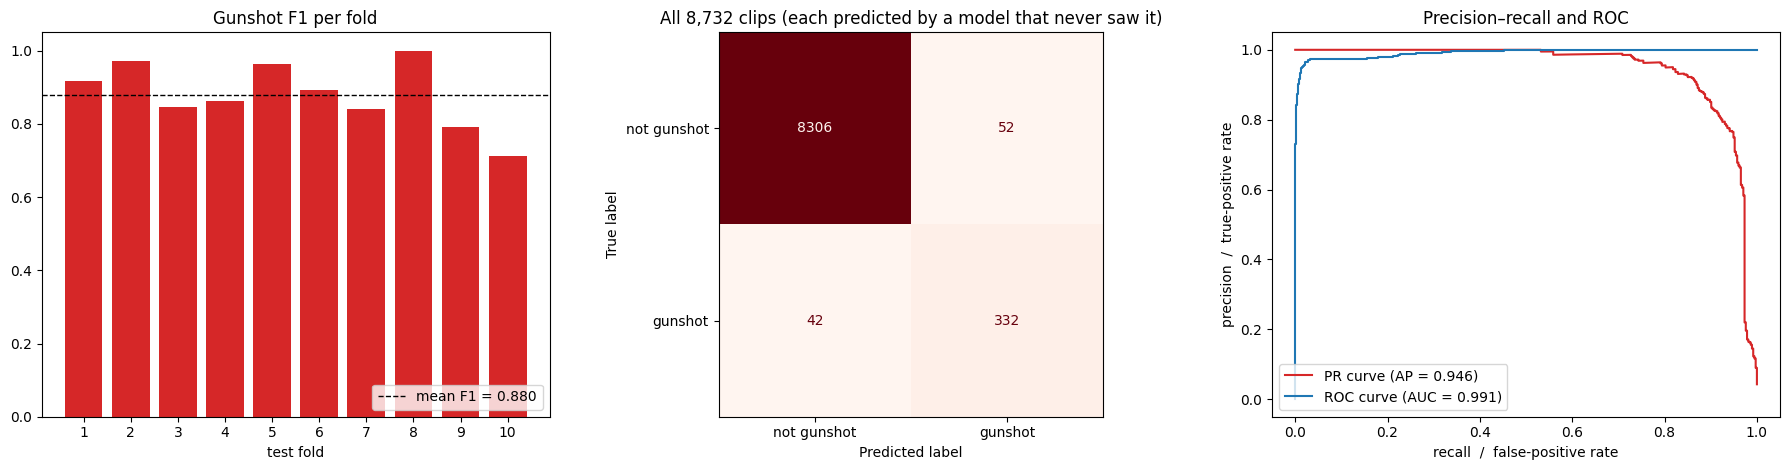

In [10]:
if RUN_CV:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    axes[0].bar(cv_df.index, cv_df['f1'], color='#d62728')
    axes[0].axhline(cv_df['f1'].mean(), color='k', ls='--', lw=1, label=f"mean F1 = {cv_df['f1'].mean():.3f}")
    axes[0].set_xticks(range(1, 11)); axes[0].set_xlabel('test fold'); axes[0].set_ylim(0, 1.05)
    axes[0].set_title('Gunshot F1 per fold'); axes[0].legend(loc='lower right')

    ConfusionMatrixDisplay(confusion_matrix(y, oof >= 0.5), display_labels=['not gunshot', 'gunshot']).plot(
        ax=axes[1], cmap='Reds', colorbar=False, values_format='d')
    axes[1].set_title('All 8,732 clips (each predicted by a model that never saw it)')

    p, r, _ = precision_recall_curve(y, oof)
    fpr, tpr, _ = roc_curve(y, oof)
    axes[2].plot(r, p, label=f'PR curve (AP = {average_precision_score(y, oof):.3f})', color='#d62728')
    axes[2].plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc_score(y, oof):.3f})', color='#1f77b4')
    axes[2].set_xlabel('recall  /  false-positive rate'); axes[2].set_ylabel('precision  /  true-positive rate')
    axes[2].set_title('Precision–recall and ROC'); axes[2].legend(loc='lower left')
    plt.tight_layout(); plt.savefig(f'{ASSET_DIR}/cross_validation.png', dpi=130); plt.show()

### What does the model mistake for a gunshot?

In [11]:
if RUN_CV:
    eval_df = meta.assign(prob=oof)
    fp = eval_df[(eval_df.is_gunshot == 0) & (eval_df.prob >= 0.5)]['class'].value_counts()
    fn = eval_df[(eval_df.is_gunshot == 1) & (eval_df.prob < 0.5)]
    print('False alarms by class:'); print(fp.to_string() if len(fp) else 'none')
    print(f'\nMissed gunshots: {len(fn)} of {int(y.sum())}')

False alarms by class:
class
air_conditioner     19
drilling             8
engine_idling        8
children_playing     5
dog_bark             5
siren                3
street_music         2
jackhammer           2

Missed gunshots: 42 of 374


### Shortcut check: is the model just detecting short clips?
If it were, short non-gunshot clips would trigger far more false alarms than full-length ones.

In [12]:
if RUN_CV:
    eval_df['length'] = pd.cut(eval_df['duration'], [0, 1, 2, 3, 3.99, 4.01], labels=['<1 s', '1–2 s', '2–3 s', '3–4 s', '4 s'])
    shortcut = eval_df[eval_df.is_gunshot == 0].groupby('length', observed=False).agg(
        clips=('prob', 'size'), false_alarm_rate=('prob', lambda p: (p >= 0.5).mean()))
    shortcut['gunshot_recall'] = eval_df[eval_df.is_gunshot == 1].groupby('length', observed=False)['prob'].apply(lambda p: (p >= 0.5).mean())
    display(shortcut.round(3))

,clips,false_alarm_rate,gunshot_recall
length,,,
<1 s,364,0.016,0.882
1–2 s,357,0.014,0.893
2–3 s,203,0.010,0.886
3–4 s,116,0.017,0.833
4 s,7318,0.005,0.938


## 5. Final model
Trained on folds 1–8, early-stopped on fold 9, tested on fold 10 (never touched during training).
The decision threshold is chosen on fold 9 to maximise F1, then applied unchanged to fold 10.

In [13]:
train_idx = np.where(folds <= 8)[0]
val_idx = np.where(folds == 9)[0]
test_idx = np.where(folds == 10)[0]

final_model, history = train(train_idx, val_idx, verbose=2)

val_prob = predict(final_model, val_idx)
p, r, t = precision_recall_curve(y[val_idx], val_prob)
f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-9)
THRESHOLD = float(t[np.argmax(f1)])
print(f'Threshold chosen on fold 9: {THRESHOLD:.3f}')

test_prob = predict(final_model, test_idx)
test_default = binary_metrics(y[test_idx], test_prob, 0.5)
test_tuned = binary_metrics(y[test_idx], test_prob, THRESHOLD)
display(pd.DataFrame({'threshold 0.5': test_default, f'threshold {THRESHOLD:.2f}': test_tuned}).T.round(3))

Epoch 1/40
111/111 - 35s - 317ms/step - auc: 0.8516 - loss: 0.6392 - pr_auc: 0.2508 - precision: 0.1548 - recall: 0.7878 - val_auc: 0.4416 - val_loss: 0.2335 - val_pr_auc: 0.0356 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/40
111/111 - 16s - 142ms/step - auc: 0.9730 - loss: 0.2110 - pr_auc: 0.6354 - precision: 0.3548 - recall: 0.9228 - val_auc: 0.8708 - val_loss: 0.6104 - val_pr_auc: 0.4042 - val_precision: 0.7143 - val_recall: 0.1613 - learning_rate: 0.0010
Epoch 3/40
111/111 - 16s - 143ms/step - auc: 0.9868 - loss: 0.1319 - pr_auc: 0.8180 - precision: 0.5051 - recall: 0.9550 - val_auc: 0.9633 - val_loss: 1.1038 - val_pr_auc: 0.7551 - val_precision: 0.0429 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/40
111/111 - 16s - 140ms/step - auc: 0.9941 - loss: 0.0921 - pr_auc: 0.9008 - precision: 0.5613 - recall: 0.9711 - val_auc: 0.9607 - val_loss: 0.1119 - val_pr_auc: 0.8074 - val_precision: 0.5581 - val_recall: 0.7742 - learning_rate: 0.0010


,threshold,precision,recall,f1,roc_auc,pr_auc,accuracy
threshold 0.5,0.500,0.968,0.938,0.952,1.0,0.996,0.996
threshold 0.25,0.251,0.941,1.000,0.970,1.0,0.996,0.998


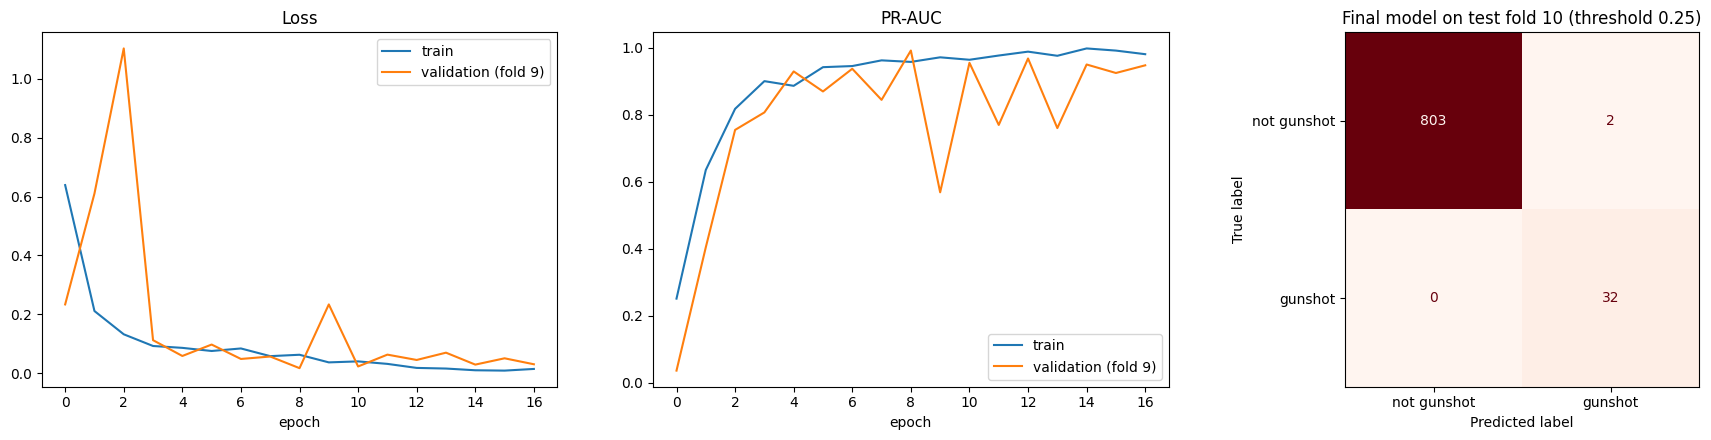

In [14]:
h = history.history
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(h['loss'], label='train'); axes[0].plot(h['val_loss'], label='validation (fold 9)')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(h['pr_auc'], label='train'); axes[1].plot(h['val_pr_auc'], label='validation (fold 9)')
axes[1].set_title('PR-AUC'); axes[1].set_xlabel('epoch'); axes[1].legend()
ConfusionMatrixDisplay(confusion_matrix(y[test_idx], test_prob >= THRESHOLD), display_labels=['not gunshot', 'gunshot']).plot(
    ax=axes[2], cmap='Reds', colorbar=False, values_format='d')
axes[2].set_title(f'Final model on test fold 10 (threshold {THRESHOLD:.2f})')
plt.tight_layout(); plt.savefig(f'{ASSET_DIR}/final_model.png', dpi=130); plt.show()

## 6. Save and package
The model is saved in Keras' native `.keras` format with a `model_info.json` that records everything the
prediction code needs. Everything is zipped so the download can't be corrupted.

In [15]:
MODEL_PATH = f'{OUT_DIR}/shotshield_v2.keras'
final_model.save(MODEL_PATH)

reloaded = keras.models.load_model(MODEL_PATH)
assert np.allclose(reloaded.predict(X[test_idx[:32]], verbose=0).ravel(), test_prob[:32], atol=1e-5), 'reload mismatch'

info = {
    'name': 'ShotShield', 'version': '2.0',
    'created': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'task': 'binary: does a 4 s audio window contain a gunshot?',
    'labels': {'0': 'not_gunshot', '1': 'gun_shot'},
    'threshold': THRESHOLD,
    'features': {'sample_rate': SAMPLE_RATE, 'clip_seconds': CLIP_SECONDS, 'n_mels': N_MELS, 'n_fft': N_FFT,
                 'hop_length': HOP_LENGTH, 'top_db': TOP_DB, 'n_frames': N_FRAMES, 'padding': 'loop'},
    'input_shape': [N_MELS, N_FRAMES, 1],
    'parameters': int(final_model.count_params()),
    'training': {'dataset': 'UrbanSound8K', 'train_folds': list(range(1, 9)), 'val_fold': 9, 'test_fold': 10,
                 'epochs_run': len(h['loss']), 'class_weighting': 'balanced'},
    'test_fold_10': {'threshold_0.5': test_default, 'tuned_threshold': test_tuned},
    'cross_validation': ({k: {'mean': float(cv_summary.loc['mean', k]), 'std': float(cv_summary.loc['std', k])}
                          for k in cv_summary.columns} if RUN_CV else None),
    'versions': {'tensorflow': tf.__version__, 'keras': keras.__version__, 'librosa': librosa.__version__},
    'model_sha256': hashlib.sha256(open(MODEL_PATH, 'rb').read()).hexdigest(),
}
with open(f'{OUT_DIR}/model_info.json', 'w') as f:
    json.dump(info, f, indent=2)

zip_path = shutil.make_archive('/kaggle/working/shotshield_v2_outputs', 'zip', OUT_DIR)
print(f'Saved {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)')
for root, _, files in os.walk(OUT_DIR):
    for name in sorted(files):
        print('  ', os.path.relpath(os.path.join(root, name), OUT_DIR))

Saved /kaggle/working/shotshield_v2_outputs.zip (3.9 MB)
   cv_results.csv
   model_info.json
   shotshield_v2.keras
   assets/cross_validation.png
   assets/dataset_overview.png
   assets/example_spectrograms.png
   assets/final_model.png


## 7. Results table for the README
Copy the output of this cell into the README's Results section.

In [16]:
def row(label, m):
    return f"| {label} | {m['precision']:.3f} | {m['recall']:.3f} | {m['f1']:.3f} | {m['roc_auc']:.3f} | {m['pr_auc']:.3f} |"

lines = ['| Evaluation | Precision | Recall | F1 | ROC-AUC | PR-AUC |', '|---|---|---|---|---|---|']
if RUN_CV:
    mean = {k: cv_summary.loc['mean', k] for k in cv_summary.columns}
    std = {k: cv_summary.loc['std', k] for k in cv_summary.columns}
    lines.append('| 10-fold CV (mean ± std) | ' + ' | '.join(f"{mean[k]:.3f} ± {std[k]:.3f}"
                 for k in ['precision', 'recall', 'f1', 'roc_auc', 'pr_auc']) + ' |')
lines.append(row(f'Final model, test fold 10 (threshold {THRESHOLD:.2f})', test_tuned))
print('\n'.join(lines))
print(f"\nParameters: {final_model.count_params():,}  |  threshold: {THRESHOLD:.3f}")

| Evaluation | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| 10-fold CV (mean ± std) | 0.892 ± 0.143 | 0.897 ± 0.128 | 0.880 ± 0.089 | 0.989 ± 0.033 | 0.966 ± 0.086 |
| Final model, test fold 10 (threshold 0.25) | 0.941 | 1.000 | 0.970 | 1.000 | 0.996 |

Parameters: 304,289  |  threshold: 0.251
